# Homework 2 Convolutions
## Will Stelter

In [19]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

## Problem 1: Which is more probable when rolling 2 six sided dice: snake eyes or a sum of seven?
#### There is only one combination of die rolls which result in snake eyes (ones on both dice). The odds of rolling this specific combination is (1/6)^2 = 1/36.
#### The odds of rolling a sum of seven is much higher, because there are multiple possible combinations of die rolls. The six possible states summing to seven are: 1-6, 2-5, 3-4, 4-3, 5-2, and 6-1. This results in a total probability of 6(1/36) = 1/6.
#### The ratio of snake eyes to sevens is (1/36)/(1/6) = 1/6

## Problem 2: Use the convolution operator to show the probability distribution for summing two six sided dice.
### Analytically
#### The probability distribution for summing two six sided dice can be written using the convolution operator P_sum = integral[ (P_1(z))(P_2(x-z)) ]
#### I'm not sure how to describe the contraction of the length of the indexes z and x - they overlap at the z = x = 1 value ?
#### Alternatively, use * as the convolution symbol P_sum = (P_1(x)) * (P_2(x))

### Numerically show the probability distribution for summing two six sided dice


In [20]:

# Goal: multiply the characteristic functions of the probability functions of two six-sided dice.
# The characterisitc function is the product of a Fourier transform

# Start by defining the probability mass function of a fair six-sided die
def fair_die_pmf(x):
    """
    Return P(X = x) for a fair six-sided die.

    The probability is 1/6 for outcomes 1 through 6,
    and zero for every other value.
    """
    x = np.asarray(x)

    return np.where(
        (x >= 1) & (x <= 6),
        1 / 6,
        0.0
    )


# List the possible outcomes, including zero for convenient array indexing
# A fair die cannot roll zero, so the probability of rolling zero is zero
die_outcomes = np.arange(0, 7)

# Calculate the probability mass functions for both dice
p_die_1 = fair_die_pmf(die_outcomes)
p_die_2 = fair_die_pmf(die_outcomes)

# Display the distributions in arrays
print("Die 1:", p_die_1)
print("Die 2:", p_die_2)
print("Total probability for die 1:", np.sum(p_die_1))

Die 1: [0.         0.16666667 0.16666667 0.16666667 0.16666667 0.16666667
 0.16666667]
Die 2: [0.         0.16666667 0.16666667 0.16666667 0.16666667 0.16666667
 0.16666667]
Total probability for die 1: 0.9999999999999999


In [21]:
# Calculate the length needed for the full linear convolution according to the formula: Final Length = (Length 1) + (Length 2) - 1
n_fft = len(p_die_1) + len(p_die_2) - 1

# Take the Fourier transforms
# NumPy pads the input arrays with zeros to length n_fft
ft_die_1 = np.fft.fft(p_die_1, n=n_fft)
ft_die_2 = np.fft.fft(p_die_2, n=n_fft)

# Display the transformed distribution of the first die
print("Fourier transform of die 1:")
print(ft_die_1)

Fourier transform of die 1:
[ 1.        +0.j         -0.08333333-0.68631175j -0.08333333+0.02053982j
 -0.08333333-0.21973194j -0.08333333+0.04373671j -0.08333333-0.12072918j
 -0.08333333+0.07382689j -0.08333333-0.07382689j -0.08333333+0.12072918j
 -0.08333333-0.04373671j -0.08333333+0.21973194j -0.08333333-0.02053982j
 -0.08333333+0.68631175j]


In [22]:
# Multiply the two Fourier transforms together, element by element
# This step is the convolution of the two probability functions
ft_sum = ft_die_1 * ft_die_2

print("Fourier transform of the sum distribution:")
print(ft_sum)

Fourier transform of the sum distribution:
[ 1.        +0.j         -0.46407937+0.11438529j  0.00652256-0.0034233j
 -0.04133768+0.03662199j  0.00503154-0.00728945j -0.00763109+0.02012153j
  0.00149403-0.01230448j  0.00149403+0.01230448j -0.00763109-0.02012153j
  0.00503154+0.00728945j -0.04133768-0.03662199j  0.00652256+0.0034233j
 -0.46407937-0.11438529j]


In [23]:
# Transform back into probability space
# Take the real part of the resulting function (there were imaginary components left over!)
p_sum_all = np.fft.ifft(ft_sum).real

# The array is indexed by the actual sum: index 0 corresponds to sum 0, index 1 to sum 1, and so on
# Sums 0 and 1 have zero probability, and should therefore be ignored
sum_values = np.arange(2, 13)

# Extract the probabilities of the possible dice sums, 2 through 12
p_sum = p_sum_all[sum_values]

# Display the results
print("Sum     Probability")
print("-------------------")

for total, probability in zip(sum_values, p_sum):
    print(f"{total:2d}      {probability:.6f}")

print(f"\nTotal probability: {np.sum(p_sum):.12f}")

Sum     Probability
-------------------
 2      0.027778
 3      0.055556
 4      0.083333
 5      0.111111
 6      0.138889
 7      0.166667
 8      0.138889
 9      0.111111
10      0.083333
11      0.055556
12      0.027778

Total probability: 1.000000000000


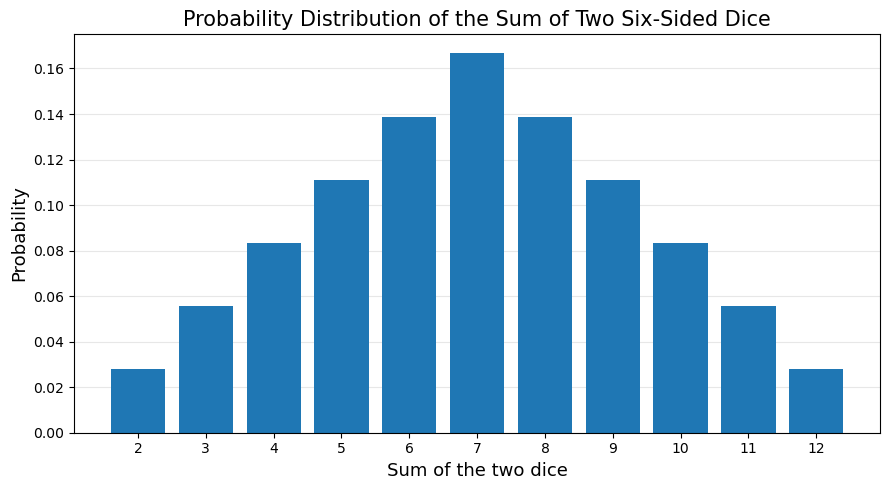

In [24]:
# Create a bar plot of the sum distribution
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(sum_values, p_sum, width=0.8)

# Label the axes and title the plot
ax.set_xlabel("Sum of the two dice", fontsize=13)
ax.set_ylabel("Probability", fontsize=13)
ax.set_title("Probability Distribution of the Sum of Two Six-Sided Dice", fontsize=15)

# Place a tick at every possible sum
ax.set_xticks(sum_values)

# Add a light grid to help compare probabilities
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [25]:
# Problem 3: Calculate the mean and variance of the two-dice sum

# The mean can be calculated by multiplying together the possible values and their probabilities, and summing those products
# sum_values and p_sum refer to these quantities, respectively. 
# np.sum performs the total summation
mean_sum = np.sum(sum_values * p_sum)

print(f"Mean of the two-dice sum: {mean_sum:.6f}")

# The variance of the two-dice sum distribution can be calculated according to the formula: 
# variance^2 = sum over all values[ difference between possible values and mean)^2 * Probability of each value ]
# Use np.sum for the total summation again, and refer to previous values
variance_sum = np.sum((sum_values - mean_sum)**2 * p_sum)

print(f"Variance of the two-dice sum: {variance_sum:.6f}")

Mean of the two-dice sum: 7.000000
Variance of the two-dice sum: 5.833333


## # Problem 4: Calculate and graph the average of 10 dice


In [31]:

# Process will be similar to the two-dice summation, with a couple differences : more dice, and a 1/10 multiple attached to the values of the rolls 
# The array index corresponds to the die outcome, including 0 
ten_p_die = np.zeros(7)

# Each  outcome from 1 through 6 has probability 1/6 (value 0 has probability 0)
ten_p_die[1:7] = 1 / 6

# Define the number of dice
ten_number_of_dice = 10

# The final convolution of 10 dice has length: 10 * (7 - 1) + 1 = 61
ten_n_fft = ten_number_of_dice * (len(ten_p_die) - 1) + 1

# Fourier transform one die
# Why is "np.fft.fft()" standard over "np.fft()" ?
ten_ft_die = np.fft.fft(ten_p_die, n=ten_n_fft)

# Raise the transofrm to the 10th power (akin to multiplying by 10)
ten_ft_sum = ten_ft_die ** ten_number_of_dice

# Take the inverse Fourier transform, and only the real part
ten_p_sum_all = np.fft.ifft(ten_ft_sum).real

# Extract the possible sums
# The sum of 10 dice ranges from 10 to 60
ten_sum_values = np.arange(10, 61)

# Extract the probabilities associated with those sums
ten_p_sum = ten_p_sum_all[ten_sum_values]

# Average the sums aka divide the possible sums by 10
ten_average_values = ten_sum_values / ten_number_of_dice

# Leave the probabilities unchanged
ten_p_average = ten_p_sum.copy()



# Calculate the mean - sum of (values*probabilities)
ten_mean_average = np.sum(ten_average_values * ten_p_average)

#Calculate the variance - (sigma^2 function)
ten_variance_average = np.sum(
    (ten_average_values - ten_mean_average)**2 * ten_p_average
)

print("TEN-DICE DISTRIBUTION")
print("---------------------")
print(f"Total probability: {np.sum(ten_p_average):.12f}")
print(f"Mean of the ten-dice average: {ten_mean_average:.6f}")
print(f"Variance of the ten-dice average: {ten_variance_average:.6f}")


TEN-DICE DISTRIBUTION
---------------------
Total probability: 1.000000000000
Mean of the ten-dice average: 3.500000
Variance of the ten-dice average: 0.291667


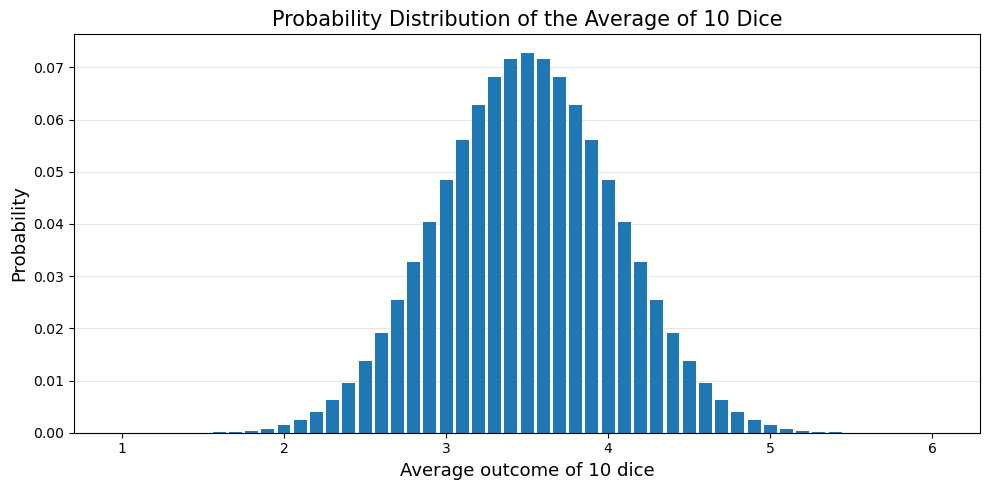

In [27]:
# Create a figure for the ten-dice average 
ten_fig, ten_ax = plt.subplots(figsize=(10, 5))

# Plot each possible average and its probability
ten_ax.bar(
    ten_average_values,
    ten_p_average,
    width=0.08
)

# Label the axes and title the plot
ten_ax.set_xlabel("Average outcome of 10 dice", fontsize=13)
ten_ax.set_ylabel("Probability", fontsize=13)
ten_ax.set_title(
    "Probability Distribution of the Average of 10 Dice",
    fontsize=15
)

# Display gridlines and space values
ten_ax.grid(axis="y", alpha=0.3)
ten_ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


### Is this a Gaussian distribution? 
#### It sure looks Gaussian! For real, this should in fact be (or at least be approaching) a Gaussian distribution, according to the Central Limit Theorem.
#### That theorem basically states that the higher your number of convolved probability distributions, the more Gaussian the final product appears
#### In the limit that you have an infinite number of distributions, the convolution will be Gaussian (unless it turns out to be either: a Dirac delta or a uniform distribution // vertical, horizontal lines, respectively)
#### I believe I could visually test the Gaussianity of this by putting it on a semi-log plot (?) If I have to code anymore right now my brain will melt

## Problem 5: Show that the sum and average of an initially Gaussian distribution is also a Gaussian. How does the standard deviation of the resulting sum or average Gaussian change?
#### Similar to above, aka due to the Central Limit THeorem, the standard deviation of convolved Gaussian distributions shrinks as the number of convolved distributions increases. Visually, the Gaussian product of a repeatedly convolved Gaussian becomes sharper and sharper. I believe this corresponds to higher precision of measurements? 
#### That is to say: if you took data and obtained many Gaussian distributions, then the convolution of that data will be more useful/meaningful/accurate. I'm not sure which adjective correctly describes the property of a data sets vailidity/usefulness/truthfulness in this case
#### In effect, this means that the longer you look at something, the more meaningful/truthful your data becomes.
#### Is the correct word "ACCURATE?" "How close a measurement is to the truth?" I mix up precision, accuracy, and validity in this context 